# 04 - Delta hedging (SIMULATED paths)
Self-financing hedge of a short European call; the same simulated paths are used for every rebalancing frequency.

In [1]:
%matplotlib inline
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from optpricer import Option, MarketData, price, price_all, bsm
pd.set_option("display.width", 160); pd.set_option("display.precision", 6)

,freq_per_year,mean_pnl,se_mean_pnl,std_pnl,q05,q95,mean_turnover_notional
0,4,0.019766,0.050952,3.222480,-5.426046,5.246759,181.299758
1,21,0.032211,0.023210,1.467903,-2.360845,2.341922,270.278736
2,252,0.004922,0.006938,0.438827,-0.711491,0.721167,624.028260
3,1000,0.001300,0.003557,0.224981,-0.355873,0.356393,1110.657290


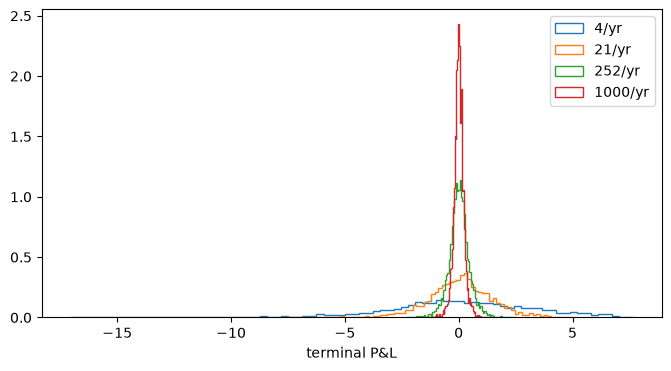

In [2]:
from optpricer.hedging import HedgeSetup, frequency_study, hedge_paths, rebalance_grid, simulate_paths, reconcile_ledger, gamma_pnl_approximation
s = HedgeSetup(S0=100, K=100, T=1.0, r=0.03, q=0.0, sigma_implied=0.2, sigma_realised=0.2, mu=0.07)
summ, pnls = frequency_study(s, (4, 21, 252, 1000), n_paths=4000, seed=42)
display(summ[["freq_per_year", "mean_pnl", "se_mean_pnl", "std_pnl", "q05", "q95", "mean_turnover_notional"]])
fig, ax = plt.subplots(figsize=(8, 4))
for f, v in pnls.items(): ax.hist(v, bins=80, histtype="step", density=True, label=f"{f}/yr")
ax.legend(); ax.set_xlabel("terminal P&L");

In [3]:
rows = []
for sr in (0.12, 0.16, 0.20, 0.24, 0.28):
    sm, _ = frequency_study(HedgeSetup(sigma_realised=sr), (252,), 2000, 7)
    rows.append({"sigma_realised": sr, "mean_pnl": sm.mean_pnl[0], "se": sm.se_mean_pnl[0]})
pd.DataFrame(rows)

,sigma_realised,mean_pnl,se
0,0.12,3.029348,0.021689
1,0.16,1.543778,0.014298
2,0.20,0.007001,0.009453
3,0.24,-1.542871,0.018645
4,0.28,-3.103834,0.034389


A short option hedged at implied volatility loses on average when realised volatility exceeds implied volatility. The gamma-weighted variance formula explains this *approximately*; it is not an exact identity for every path.

In [4]:
t = rebalance_grid(1.0, 21)
sq = HedgeSetup(q=0.02, cost_rate=0.001)
S = simulate_paths(sq, t, 1, np.random.default_rng(1))
out = hedge_paths(sq, t, S, ledger_path=0)
display(out["ledger"].round(5).head(8))
reconcile_ledger(out["ledger"], sq.r, sq.T)

,t,S,premium,shares_traded,trade_cash,cost,interest,dividend,payoff,liquidation,delta_held,cash,option_mark,portfolio_value
0,0.00000,100.00000,8.26633,0.54854,-54.85365,-0.05485,0.00000,0.00000,0.0,0.0,0.54854,-46.64218,8.26633,-0.05485
1,0.04762,101.66482,0.00000,0.03164,-3.21679,-0.00322,-0.06668,0.05268,0.0,0.0,0.58018,-49.87618,9.00435,0.10312
2,0.09524,105.52714,0.00000,0.07266,-7.66711,-0.00767,-0.07130,0.05724,0.0,0.0,0.65283,-57.56502,11.18084,0.14573
3,0.14286,107.21308,0.00000,0.03205,-3.43659,-0.00344,-0.08229,0.06614,0.0,0.0,0.68489,-61.02121,12.10186,0.30575
4,0.19048,101.43035,0.00000,-0.10960,11.11630,-0.01112,-0.08724,0.06805,0.0,0.0,0.57529,-49.93521,8.23050,0.18630
5,0.23810,105.66925,0.00000,0.08703,-9.19653,-0.00920,-0.07139,0.05673,0.0,0.0,0.66232,-59.15559,10.63165,0.19990
6,0.28571,107.90205,0.00000,0.04543,-4.90170,-0.00490,-0.08457,0.06736,0.0,0.0,0.70775,-64.07940,11.93856,0.34971
7,0.33333,105.55349,0.00000,-0.04180,4.41234,-0.00441,-0.09161,0.07194,0.0,0.0,0.66595,-59.69114,10.09437,0.50763


{'future_value_of_flows': 2.904048761254799,
 'final_cash': 2.904048761254804,
 'difference': 4.884981308350689e-15}

In [5]:
t = rebalance_grid(1.0, 252); s2 = HedgeSetup(sigma_realised=0.25)
S = simulate_paths(s2, t, 2000, np.random.default_rng(3))
act, apx = hedge_paths(s2, t, S)["pnl"], gamma_pnl_approximation(s2, t, S)
print("corr(actual, gamma approximation) =", round(np.corrcoef(act, apx)[0, 1], 4),
      "; RMS difference =", round(float(np.sqrt(np.mean((act - apx) ** 2))), 4))

corr(actual, gamma approximation) = 0.997 ; RMS difference = 0.0782
